# Frames, kinematics and rotations

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/3_robot_learning/01_kinematics.ipynb) &nbsp; Guide note: [guide-robotics-fundamentals](https://www.matthewwnuk.com/guide-robotics-fundamentals.html)

The classical layer that every learned policy sits on, worked through for a two-link arm: transforms
that chain, forward and inverse kinematics, the Jacobian and what happens near a singularity, and why a
rotation should not be written as a single angle.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from guide_utils import style
style.use(); L1, L2 = 1.0, 0.85

## Transforms chain by multiplication

A pose is a rotation and a translation, packed into one matrix. `T_ab` is the pose of frame b seen from
frame a. To move a point from the camera frame to the robot's base frame, multiply by `T_base_camera`.

In [3]:
def T(theta, x, y):
    c, s = np.cos(theta), np.sin(theta); return np.array([[c, -s, x], [s, c, y], [0, 0, 1.0]])

T_base_camera = T(np.radians(-145), 1.6, 1.2)                # from calibration
T_camera_object = T(np.radians(30), 0.9, 0.25)               # from perception
T_base_object = T_base_camera @ T_camera_object              # inner frames match and cancel
print("object in the base frame:", T_base_object[:2, 2].round(3))
print("inverse undoes it:       ", (np.linalg.inv(T_base_camera) @ T_base_object)[:2, 2].round(3), "=", T_camera_object[:2, 2])
off = T_base_camera @ T(np.radians(2), 0, 0) @ T_camera_object     # a 2 degree calibration error
print(f"a 2 degree error in the camera's angle moves the object by {np.linalg.norm(off[:2, 2] - T_base_object[:2, 2]) * 100:.1f} cm at this distance")

object in the base frame: [1.006 0.479]
inverse undoes it:        [0.9  0.25] = [0.9  0.25]
a 2 degree error in the camera's angle moves the object by 3.3 cm at this distance


## Forward and inverse kinematics

Forward kinematics turns joint angles into the hand's position. It has one answer. Inverse kinematics
goes the other way and can have two answers, or none.

elbow up  : [ 65.5 -76.3] degrees
elbow down: [-3.5 76.3] degrees
out of reach: None


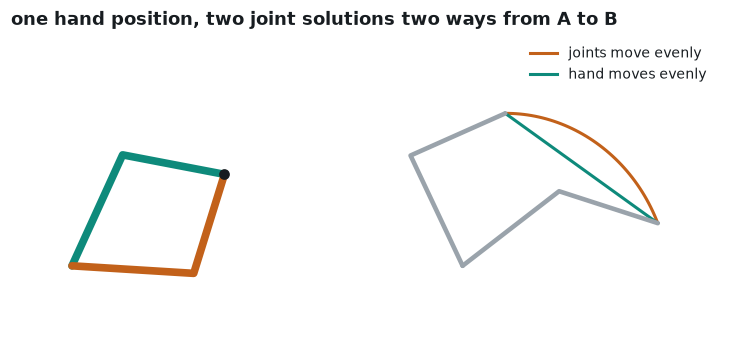

In [4]:
def fk(q):
    elbow = np.array([L1 * np.cos(q[0]), L1 * np.sin(q[0])]); return elbow, elbow + np.array([L2 * np.cos(q[0] + q[1]), L2 * np.sin(q[0] + q[1])])

def ik(p, elbow_up=True):
    c = (p @ p - L1 ** 2 - L2 ** 2) / (2 * L1 * L2)
    if abs(c) > 1: return None                                # out of reach
    q2 = np.arccos(c) * (-1 if elbow_up else 1); q1 = np.arctan2(p[1], p[0]) - np.arctan2(L2 * np.sin(q2), L1 + L2 * np.cos(q2)); return np.array([q1, q2])

def draw(ax, q, color, lw=5):
    e, h = fk(q); ax.plot([0, e[0], h[0]], [0, e[1], h[1]], color=color, lw=lw, solid_capstyle="round", solid_joinstyle="round")

target = np.array([1.25, 0.75]); fig, ax = plt.subplots(1, 2, figsize=(8.4, 3.6))
for up, c in ((True, style.TEAL), (False, style.ORANGE)): draw(ax[0], ik(target, up), c)
ax[0].plot(*target, "o", color=style.INK); ax[0].set_title("one hand position, two joint solutions")
print("elbow up  :", np.degrees(ik(target, True)).round(1), "degrees"); print("elbow down:", np.degrees(ik(target, False)).round(1), "degrees"); print("out of reach:", ik(np.array([1.9, 1.2])))
a, b = np.array([0.35, 1.25]), np.array([1.6, 0.35]); qa, qb = ik(a), ik(b)
joint_path = np.array([fk(qa + s * (qb - qa))[1] for s in np.linspace(0, 1, 50)])
ax[1].plot(*joint_path.T, color=style.ORANGE, label="joints move evenly"); ax[1].plot([a[0], b[0]], [a[1], b[1]], color=style.TEAL, label="hand moves evenly")
draw(ax[1], qa, style.GREY, 3); draw(ax[1], qb, style.GREY, 3); ax[1].legend(fontsize=9); ax[1].set_title("two ways from A to B")
for x in ax: x.set_aspect("equal"); x.set_xlim(-0.5, 2.1); x.set_ylim(-0.6, 1.9); style.bare(x)
plt.show()

## The Jacobian

The Jacobian relates small joint motions to small hand motions: `dx = J dq`. Its singular values say how
far the hand moves in each direction for a unit of joint motion, which can be drawn as an ellipse.
As the arm straightens the ellipse collapses: the hand can no longer move along the arm.

matches a numerical derivative: True


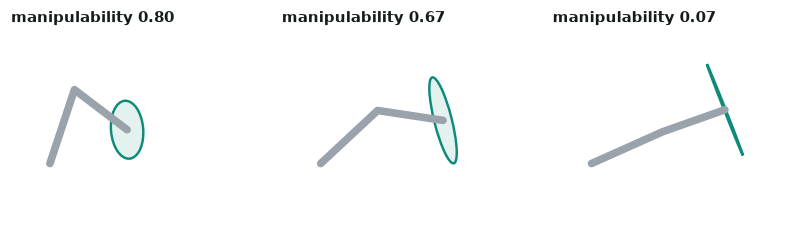

In [5]:
def jacobian(q):
    s1, c1, s12, c12 = np.sin(q[0]), np.cos(q[0]), np.sin(q[0] + q[1]), np.cos(q[0] + q[1])
    return np.array([[-L1 * s1 - L2 * s12, -L2 * s12], [L1 * c1 + L2 * c12, L2 * c12]])

q = np.array([0.8, -1.2]); eps = 1e-6; numeric = np.column_stack([(fk(q + eps * np.eye(2)[i])[1] - fk(q)[1]) / eps for i in range(2)])
print("matches a numerical derivative:", np.allclose(jacobian(q), numeric, atol=1e-5))
fig, ax = plt.subplots(1, 3, figsize=(9, 3.1))
for a_, q in zip(ax, ([1.25, -1.9], [0.75, -0.9], [0.42, -0.08])):
    q = np.array(q); U, S, _ = np.linalg.svd(jacobian(q)); h = fk(q)[1]; draw(a_, q, style.GREY)
    a_.add_patch(Ellipse(h, 0.62 * S[0], 0.62 * S[1], angle=np.degrees(np.arctan2(U[1, 0], U[0, 0])), fc="#E3F2EF", ec=style.TEAL, lw=1.6))
    a_.set_title(f"manipulability {S[0] * S[1]:.2f}", fontsize=10); a_.set_aspect("equal"); a_.set_xlim(-0.5, 2.4); a_.set_ylim(-0.7, 1.7); style.bare(a_)
plt.show()

Near a singularity, a small requested hand motion needs enormous joint speeds. Ask for the same 1 cm
step along the arm at different amounts of stretch.

In [6]:
step = 0.01; rows = []
for bend in (1.2, 0.6, 0.3, 0.1, 0.03):
    q = np.array([0.4, -bend]); h = fk(q)[1]; along = h / np.linalg.norm(h)
    dq = np.linalg.pinv(jacobian(q)) @ (along * step); lam = 0.05; J = jacobian(q); dq_damped = J.T @ np.linalg.solve(J @ J.T + lam ** 2 * np.eye(2), along * step)
    rows.append((np.degrees(bend), np.degrees(np.abs(dq).max()), np.degrees(np.abs(dq_damped).max())))
    print(f"elbow bent {rows[-1][0]:5.1f} deg: joint must turn {rows[-1][1]:7.2f} deg   with damping {rows[-1][2]:5.2f} deg")

elbow bent  68.8 deg: joint must turn    1.11 deg   with damping  1.09 deg
elbow bent  34.4 deg: joint must turn    2.11 deg   with damping  2.03 deg
elbow bent  17.2 deg: joint must turn    4.17 deg   with damping  3.60 deg
elbow bent   5.7 deg: joint must turn   12.48 deg   with damping  5.12 deg
elbow bent   1.7 deg: joint must turn   41.57 deg   with damping  2.45 deg


## Rotations are not ordinary numbers

A gripper turning steadily. Written as one angle, the value jumps from +180 to -180 where nothing
physical happened. Written as a cosine and a sine it is smooth. Averaging two almost identical poses on
either side of the jump shows the damage.

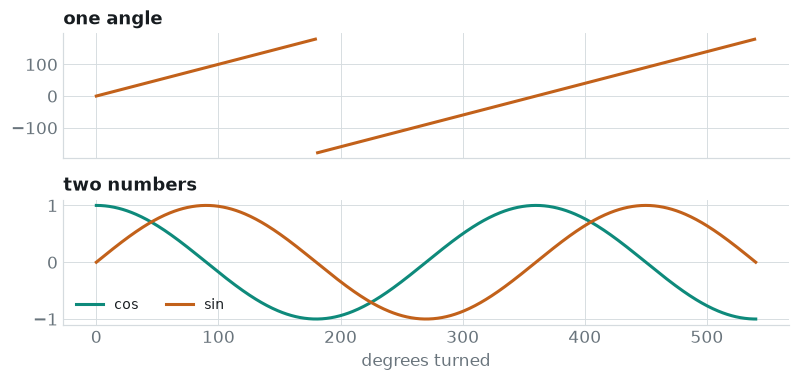

two poses 2 degrees apart: 179.0 and -179.0
averaging the angles gives 0.0 degrees: pointing the opposite way
averaging (cos, sin) gives 180 degrees: correct


In [7]:
theta = np.linspace(0, 540, 600); wrapped = (theta + 180) % 360 - 180; fig, ax = plt.subplots(2, 1, figsize=(7.4, 3.6), sharex=True)
w = wrapped.copy(); w[np.flatnonzero(np.abs(np.diff(w)) > 180) + 1] = np.nan; ax[0].plot(theta, w, color=style.ORANGE); ax[0].set_title("one angle")
ax[1].plot(theta, np.cos(np.radians(theta)), label="cos"); ax[1].plot(theta, np.sin(np.radians(theta)), label="sin"); ax[1].set_title("two numbers"); ax[1].legend(ncol=2, fontsize=9); ax[1].set_xlabel("degrees turned"); plt.tight_layout(); plt.show()
a, b = 179.0, -179.0; mean_angle = (a + b) / 2; v = (np.array([np.cos(np.radians(a)), np.sin(np.radians(a))]) + np.array([np.cos(np.radians(b)), np.sin(np.radians(b))])) / 2
print(f"two poses 2 degrees apart: {a} and {b}"); print(f"averaging the angles gives {mean_angle} degrees: pointing the opposite way"); print(f"averaging (cos, sin) gives {np.degrees(np.arctan2(v[1], v[0])):.0f} degrees: correct")

## Things to try

- Add a third link. How many inverse-kinematics solutions are there now?
- Solve inverse kinematics by iterating `q += pinv(J) @ (target - fk(q))` from a random start.
- Plot manipulability over the whole workspace as a heat map.